# Drawing interaction nets

A test of drawing `inets` nets in a notebook. With Graphviz's `dot` installed, the pictures are
made locally; in JupyterLite, viz.js (Graphviz compiled to WebAssembly) draws them in the page.

In [1]:
try:
    import inets
except ImportError:
    %pip install -q inets
    import inets
print(inets.__version__)

0.1.3


In [2]:
import json
import shutil
import subprocess
import uuid

from IPython.display import HTML, SVG

VIZ = "https://cdn.jsdelivr.net/npm/@viz-js/viz@3.31.0/+esm"
DRAW_UP_TO = 80  # nodes: larger nets are described, not drawn (as in the inets kernel)


def _svg(dot):
    """Graphviz text as SVG from a local ``dot``, or None."""
    program = shutil.which("dot")
    if program is None:
        return None
    try:
        r = subprocess.run([program, "-Tsvg"], input=dot, capture_output=True, text=True, timeout=30)
    except (OSError, subprocess.SubprocessError):
        return None
    return r.stdout[r.stdout.index("<svg"):] if r.returncode == 0 and "<svg" in r.stdout else None


def draw(net, names=None):
    if len(net.kind) > DRAW_UP_TO:
        return HTML(f"<p>{len(net.kind)} nodes: too many to draw.</p>")
    dot = net.dot(names)
    svg = _svg(dot)
    if svg is not None:
        return SVG(svg)
    box = "net-" + uuid.uuid4().hex
    text = json.dumps(dot).replace("</", "<\\/")
    return HTML(f"""<div id="{box}">drawing the net&hellip;</div>
<script>
import("{VIZ}")
  .then(viz => viz.instance())
  .then(viz => document.getElementById("{box}").replaceChildren(viz.renderSVGElement({text})))
  .catch(e => {{ document.getElementById("{box}").textContent = "viz.js could not draw the net: " + e; }});
</script>""")

## A constructor meets a duplicator

The example from the README, in the `combinators` table. The thick red wire is the active pair;
the numbers at the ends of a wire are port numbers, 0 being the principal port.

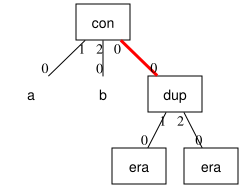

In [3]:
net = inets.Net(inets.bundled("combinators"))
a, b = net.free(), net.free()
net.wire(net.make("con", a, b), net.make("dup", net.make("era"), net.make("era")))
draw(net, {a: "a", b: "b"})

Result(reason='normal', interactions=3, counts={'commute': 1, 'erase': 2}, active_left=0, rounds=0, widest=0)


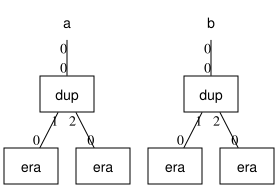

In [4]:
print(net.reduce())
draw(net, {a: "a", b: "b"})

## S K K I, by need

The same term the `inets run ski` command reads. It reduces to `I`.

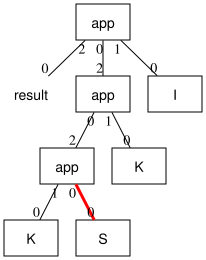

In [5]:
from inets import ski

net = inets.Net(inets.bundled("ski"))
out = net.free()
net.wire(ski.encode(net, ski.parse("```SKKI")), out)
draw(net, {out: "result"})

Result(reason='wanted', interactions=6, counts={'collect': 3, 'contract': 2, 'copy': 1}, active_left=1, rounds=0, widest=0)
I


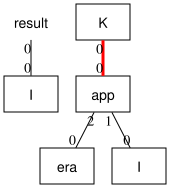

In [6]:
print(net.reduce_by_need(out))
print(ski.show(ski.read_back(net, out)))
draw(net, {out: "result"})